In [1]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
import matplotlib.pyplot as plt

In [3]:
from tensorflow.keras.datasets import imdb
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 25000
Testing samples: 25000


**Check Sequence Labels**

In [4]:
import numpy as np
lengths = [len(word) for word in X_train]
print("Minimum length:", min(lengths))
print("Maximum length:", max(lengths))
print("Average length:", np.mean(lengths))

Minimum length: 11
Maximum length: 2494
Average length: 238.71364


**Padding**

In [5]:
MAX_LEN = 100
X_train_padded = pad_sequences(X_train,maxlen=MAX_LEN,padding="post",truncating="post")
X_test_padded = pad_sequences(X_test,maxlen=MAX_LEN,padding="post",truncating="post")

In [6]:
# Verifying target labels
print(y_train.shape)
print(y_test.shape)

print(y_train[:10])
print(y_test[:10])

(25000,)
(25000,)
[1 0 0 1 0 0 1 0 1 0]
[0 1 1 0 1 1 1 0 0 1]


In [7]:
# Checking Shapes after Padding
print("X_train shape:", X_train_padded.shape)
print("X_test shape :", X_test_padded.shape)

X_train shape: (25000, 100)
X_test shape : (25000, 100)


**Building Model**

In [8]:
model = Sequential([Embedding(input_dim=10000,output_dim=128,input_length=100),
                    LSTM(128),Dropout(0.5),Dense(1,activation="sigmoid")])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Training Model**

In [11]:
history = model.fit(X_train_padded,y_train,epochs=5,batch_size=64,validation_split=0.2)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 71s 219ms/step - accuracy: 0.7204 - loss: 0.5433 - val_accuracy: 0.8062 - val_loss: 0.4444
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 69s 221ms/step - accuracy: 0.8254 - loss: 0.4477 - val_accuracy: 0.7932 - val_loss: 0.4742
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 222ms/step - accuracy: 0.8512 - loss: 0.3798 - val_accuracy: 0.8178 - val_loss: 0.4543
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 222ms/step - accuracy: 0.8885 - loss: 0.3014 - val_accuracy: 0.8126 - val_loss: 0.4379
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 219ms/step - accuracy: 0.9182 - loss: 0.2356 - val_accuracy: 0.8212 - val_loss: 0.4343


In [12]:
# Generate Predictions
y_pred_proba = model.predict(X_test_padded)

782/782 ━━━━━━━━━━━━━━━━━━━━ 36s 46ms/step


In [13]:
y_pred = (y_pred_proba > 0.5).astype(int)

**MODEL EVALUATION**

In [14]:
test_loss, test_accuracy = model.evaluate(X_test_padded,y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 36s 45ms/step - accuracy: 0.7988 - loss: 0.4835


**Classification Report**

In [15]:
print("\nClassification Report")
print(classification_report(y_test,y_pred,target_names=["Negative", "Positive"]))


Classification Report
              precision    recall  f1-score   support

    Negative       0.80      0.80      0.80     12500
    Positive       0.80      0.80      0.80     12500

    accuracy                           0.80     25000
   macro avg       0.80      0.80      0.80     25000
weighted avg       0.80      0.80      0.80     25000



**Confusion Matrix**

In [16]:
cm = confusion_matrix(y_test,y_pred)

**Visualisation of Confusion Matrix**

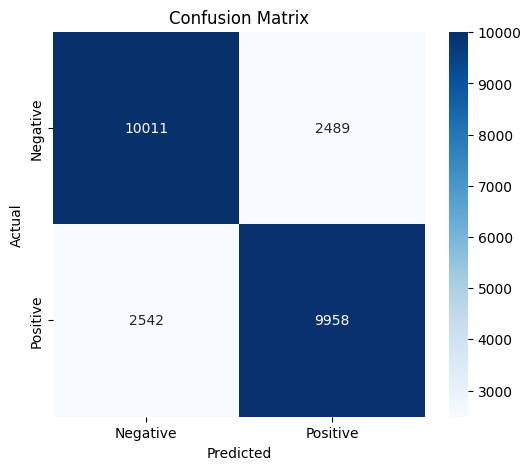

In [17]:
import seaborn as sns
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d",cmap="Blues",xticklabels=["Negative", "Positive"],yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**TRAINING VS VALIDATION ACCURACY**

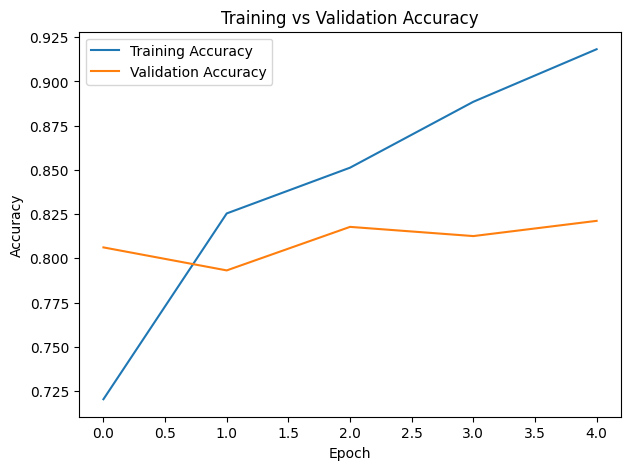

In [18]:
plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title( "Training vs Validation Accuracy")
plt.legend()
plt.show()

**TRAINING VS VALIDATION LOSS**

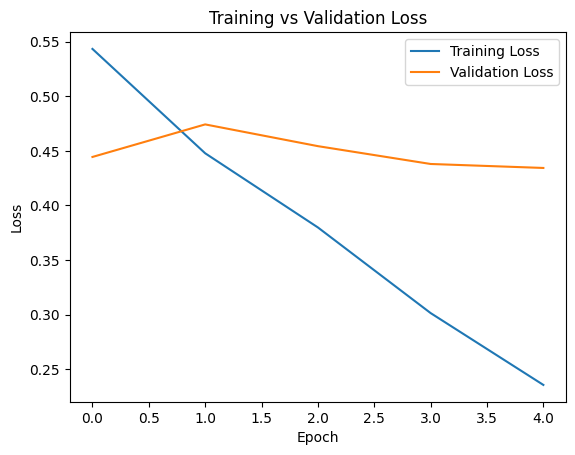

In [19]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

In [20]:
for i in range(10):
    print("Review:", i)
    print("Actual:", y_test[i])
    print("Predicted:", y_pred[i])
    print()

Review: 0
Actual: 0
Predicted: [0]

Review: 1
Actual: 1
Predicted: [1]

Review: 2
Actual: 1
Predicted: [1]

Review: 3
Actual: 0
Predicted: [0]

Review: 4
Actual: 1
Predicted: [1]

Review: 5
Actual: 1
Predicted: [1]

Review: 6
Actual: 1
Predicted: [0]

Review: 7
Actual: 0
Predicted: [1]

Review: 8
Actual: 0
Predicted: [1]

Review: 9
Actual: 1
Predicted: [0]



In [21]:
# Trying with new Review
word_index = imdb.get_word_index()

# Create the same mapping used by Keras IMDB
word_index = {word: (index + 3) for word, index in word_index.items()}

# Special tokens
word_index[""] = 0
word_index[""] = 1
word_index[""] = 2
word_index[""] = 3

review = input("Enter your review: ")
print("The review entered is:", review)

sequence = [word_index.get(word.lower(), 2)
            if word_index.get(word.lower(), 2) < 10000
            else 2
            for word in review.split()
]

sequence_padded = pad_sequences(
    [sequence],
    maxlen=100,
    padding='post',
    truncating='post'
)
prediction = model.predict(sequence_padded)[0][0]

print("Probability:", prediction)

if prediction >= 0.5:
    print("Predicted Sentiment: Positive")
else:
    print("Predicted Sentiment: Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Enter your review: It is so nice
The review entered is: It is so nice
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Probability: 0.9059571
Predicted Sentiment: Positive
